# LesioScan — Notebook 03: ShuffleNet V2 Training

**Goal:** train pretrained ShuffleNet V2 in two stages using **train/val only**. The final **test set remains sealed** for Notebook 05. Dataset images stay on Google Drive; no copies are created.

## 1. GPU, Drive, dan GitHub

In [1]:
import torch
print('PyTorch:',torch.__version__)
print('GPU available:',torch.cuda.is_available())
if torch.cuda.is_available(): print('GPU:',torch.cuda.get_device_name(0))
else: raise RuntimeError('Aktifkan GPU: Runtime → Change runtime type → T4 GPU')

PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [5]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import subprocess, sys, os
REPO=Path('/content/lesioscan-ml')
if not REPO.exists(): subprocess.run(['git','clone','https://github.com/Liex2810/lesioscan-ml.git',str(REPO)],check=True)
else: subprocess.run(['git','pull','--ff-only','origin','main'],cwd=REPO,check=True)
os.chdir(REPO)
for name in ['scripts/train_lesioscan.py','src/lesioscan/training.py','src/lesioscan/dataset.py','src/lesioscan/preprocessing.py']:
    assert (REPO/name).is_file(),f'Missing: {name}. Push file training terlebih dahulu.'
print('✅ Source Python siap')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Source Python siap


## 2. Konfigurasi eksperimen

In [6]:
DRIVE=Path('/content/drive/MyDrive/LesioScan-AI')
DATASET=DRIVE/'datasets/PAD-UFES-20'
SPLIT=DRIVE/'experiments/splits/split.csv'
TRAIN_OUT=DRIVE/'experiments/training/shufflenet_v2_baseline'
assert SPLIT.is_file(),SPLIT
assert DATASET.is_dir(),DATASET
TRAIN_OUT.mkdir(parents=True,exist_ok=True)
EPOCHS_HEAD=5
EPOCHS_FINETUNE=20
BATCH_SIZE=16
SEED=42
print('Input:',SPLIT,'\nOutput:',TRAIN_OUT)

Input: /content/drive/MyDrive/LesioScan-AI/experiments/splits/split.csv 
Output: /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline


## 3. Audit data tanpa membaca seluruh gambar

In [7]:
import pandas as pd
df=pd.read_csv(SPLIT)
print('Rows:',len(df))
display(pd.crosstab(df.diagnostic,df.split))
assert len(df)==2298
assert set(df.split)=={'train','val','test'}
patients={s:set(df.loc[df.split==s,'patient_id']) for s in ['train','val','test']}
assert patients['train'].isdisjoint(patients['val'])
assert patients['train'].isdisjoint(patients['test'])
assert patients['val'].isdisjoint(patients['test'])
print('✅ Patient-level isolation benar')

Rows: 2298


split,test,train,val
diagnostic,,,
ACK,115,504,111
BCC,130,591,124
MEL,8,37,7
NEV,36,177,31
SCC,32,130,30
SEK,30,169,36


✅ Patient-level isolation benar


## 4. Training — Stage 1 + Stage 2

**Stage 1:** Freeze backbone, train classifier head. **Stage 2:** Unfreeze all layers and fine-tune with smaller learning rate. Weighted Cross Entropy is calculated using **training labels only**. `best_shufflenetv2.pt` is selected by validation Macro-F1, never by test performance.

In [10]:
from pathlib import Path
import ast

TRAINING_MODULE = REPO / "src/lesioscan/training.py"

source = TRAINING_MODULE.read_text(encoding="utf-8")

OLD_CODE = """    for images, labels in tqdm(loader, desc=desc, leave=False):
"""

NEW_CODE = """    total_batches = len(loader)

    print(
        f"[BATCH_START] {stage} "
        f"{'train' if is_training else 'val'} "
        f"{epoch}/{epochs} total={total_batches}",
        flush=True
    )

    for batch_index, (images, labels) in enumerate(
        tqdm(loader, desc=desc, leave=False),
        start=1
    ):
"""

OLD_END = """        y_pred.extend(scores.argmax(1).detach().cpu().tolist())
"""

NEW_END = """        y_pred.extend(scores.argmax(1).detach().cpu().tolist())

        print(
            f"[BATCH_PROGRESS] {stage} "
            f"{'train' if is_training else 'val'} "
            f"{epoch}/{epochs} "
            f"{batch_index}/{total_batches} "
            f"loss={loss.item():.4f}",
            flush=True
        )
"""

if "[BATCH_PROGRESS]" not in source:

    if OLD_CODE not in source:
        raise RuntimeError(
            "Loop DataLoader berbeda dari versi yang diperiksa."
        )

    if OLD_END not in source:
        raise RuntimeError(
            "Bagian akhir loop training tidak ditemukan."
        )

    source = source.replace(OLD_CODE, NEW_CODE, 1)
    source = source.replace(OLD_END, NEW_END, 1)

    ast.parse(source)

    TRAINING_MODULE.write_text(
        source,
        encoding="utf-8"
    )

print("✅ Batch progress monitoring aktif!")

✅ Batch progress monitoring aktif!


In [11]:
import subprocess
import sys
import re
import time
import threading
import math

import pandas as pd
import ipywidgets as widgets

from IPython.display import display


# =============================================
# LESIOSCAN TRAINING CONFIGURATION
# =============================================

HEAD_EPOCHS = int(EPOCHS_HEAD)
FT_EPOCHS = int(EPOCHS_FINETUNE)

TOTAL_EPOCHS = HEAD_EPOCHS + FT_EPOCHS

if TOTAL_EPOCHS <= 0:
    raise ValueError("Total epoch harus positif.")


# =============================================
# DATASET INFORMATION
# =============================================

split_df = pd.read_csv(SPLIT)

train_count = int((split_df["split"] == "train").sum())
val_count = int((split_df["split"] == "val").sum())

train_batches = math.ceil(train_count / BATCH_SIZE)
val_batches = math.ceil(val_count / BATCH_SIZE)

batches_per_epoch = train_batches + val_batches

print(f"Training images   : {train_count}")
print(f"Validation images : {val_count}")
print(f"Train batches     : {train_batches}")
print(f"Validation batches: {val_batches}")


# =============================================
# DASHBOARD
# =============================================

def make_bar(title):
    return widgets.FloatProgress(
        value=0,
        min=0,
        max=100,
        description=title,
        bar_style="info",
        layout=widgets.Layout(width="750px")
    )


overall_bar = make_bar("Overall:")
head_bar = make_bar("Stage 1:")
ft_bar = make_bar("Stage 2:")
epoch_bar = make_bar("Epoch:")

overall_label = widgets.HTML("<b>Overall: 0.0%</b>")
head_label = widgets.HTML("<b>Feature Extraction: 0.0%</b>")
ft_label = widgets.HTML("<b>Fine-Tuning: 0.0%</b>")
epoch_label = widgets.HTML("<b>Epoch: 0.0%</b>")

stage_status = widgets.HTML("Stage: Initializing...")
batch_status = widgets.HTML("Batch: Belum dimulai")
loss_status = widgets.HTML("Loss: Belum tersedia")
metrics_status = widgets.HTML("Validation: Belum tersedia")
time_status = widgets.HTML("Elapsed: 00:00:00")

dashboard = widgets.VBox([
    widgets.HTML(
        "<h3>🔬 LesioScan — ShuffleNet V2 Training Monitor</h3>"
    ),

    overall_bar,
    overall_label,

    head_bar,
    head_label,

    ft_bar,
    ft_label,

    epoch_bar,
    epoch_label,

    stage_status,
    batch_status,
    loss_status,
    metrics_status,
    time_status
])

display(dashboard)


# =============================================
# TRAINING COMMAND
# =============================================

command = [
    sys.executable,
    "-u",
    "scripts/train_lesioscan.py",

    "--split", str(SPLIT),
    "--images", str(DATASET),
    "--out", str(TRAIN_OUT),

    "--epochs-head", str(HEAD_EPOCHS),
    "--epochs-finetune", str(FT_EPOCHS),

    "--batch-size", str(BATCH_SIZE),
    "--seed", str(SEED)
]


# =============================================
# START PROCESS
# =============================================

started_at = time.monotonic()

process = subprocess.Popen(
    command,
    cwd=REPO,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
    errors="replace"
)

stop_event = threading.Event()


def update_clock():

    while not stop_event.wait(1):

        elapsed = int(time.monotonic() - started_at)

        hours = elapsed // 3600
        minutes = (elapsed % 3600) // 60
        seconds = elapsed % 60

        time_status.value = (
            f"<b>Elapsed:</b> "
            f"{hours:02}:{minutes:02}:{seconds:02}"
        )


clock_thread = threading.Thread(
    target=update_clock,
    daemon=True
)

clock_thread.start()


# =============================================
# TRAINING STATE
# =============================================

completed_head = 0
completed_ft = 0

current_stage = None
current_epoch = 0

current_train_batch = 0
current_val_batch = 0

current_train_total = train_batches
current_val_total = val_batches

logs = []


# =============================================
# REGEX
# =============================================

batch_regex = re.compile(
    r"\[BATCH_PROGRESS\]\s+"
    r"(feature_extraction|fine_tuning)\s+"
    r"(train|val)\s+"
    r"(\d+)/(\d+)\s+"
    r"(\d+)/(\d+)\s+"
    r"loss=([\d.eE+-]+)"
)

epoch_regex = re.compile(
    r"\[TRAIN\]\s+"
    r"(feature_extraction|fine_tuning)\s+"
    r"(\d+)/(\d+)\s+\|\s+"
    r"train_loss=([\d.eE+-]+)\s+"
    r"val_loss=([\d.eE+-]+)\s+"
    r"val_macro_f1=([\d.eE+-]+)"
)


# =============================================
# UPDATE DASHBOARD
# =============================================

def update_dashboard():

    total_current = current_train_total + current_val_total

    processed_current = (
        current_train_batch + current_val_batch
    )

    epoch_progress = (
        processed_current / total_current
        if total_current > 0
        else 0
    )

    epoch_progress = min(1.0, epoch_progress)

    epoch_bar.value = epoch_progress * 100
    epoch_label.value = (
        f"<b>Current Epoch: {epoch_progress * 100:.1f}%</b>"
    )

    head_progress = completed_head

    ft_progress = completed_ft

    if current_stage == "feature_extraction":
        head_progress += epoch_progress

    elif current_stage == "fine_tuning":
        ft_progress += epoch_progress

    if HEAD_EPOCHS > 0:
        head_pct = min(
            100,
            head_progress / HEAD_EPOCHS * 100
        )
    else:
        head_pct = 100

    if FT_EPOCHS > 0:
        ft_pct = min(
            100,
            ft_progress / FT_EPOCHS * 100
        )
    else:
        ft_pct = 100

    overall_pct = min(
        100,
        (
            head_progress + ft_progress
        ) / TOTAL_EPOCHS * 100
    )

    overall_bar.value = overall_pct
    head_bar.value = head_pct
    ft_bar.value = ft_pct

    overall_label.value = (
        f"<b>Overall: {overall_pct:.2f}%</b>"
    )

    head_label.value = (
        f"<b>Feature Extraction: {head_pct:.2f}%</b>"
    )

    ft_label.value = (
        f"<b>Fine-Tuning: {ft_pct:.2f}%</b>"
    )

    batch_status.value = (
        f"<b>Train:</b> "
        f"{current_train_batch}/{current_train_total} batches"
        "<br>"
        f"<b>Validation:</b> "
        f"{current_val_batch}/{current_val_total} batches"
    )


# =============================================
# PROCESS OUTPUT
# =============================================

try:

    for line in process.stdout:

        line = line.strip()

        if not line:
            continue

        logs.append(line)

        if len(logs) > 200:
            logs.pop(0)

        batch_match = batch_regex.search(line)

        # -------------------------------------
        # BATCH PROGRESS
        # -------------------------------------

        if batch_match:

            stage = batch_match.group(1)
            mode = batch_match.group(2)

            epoch = int(batch_match.group(3))
            batch = int(batch_match.group(5))
            total = int(batch_match.group(6))
            loss = float(batch_match.group(7))

            if (
                stage != current_stage
                or epoch != current_epoch
            ):

                current_stage = stage
                current_epoch = epoch

                current_train_batch = 0
                current_val_batch = 0

            if mode == "train":

                current_train_batch = batch
                current_train_total = total

            else:

                current_val_batch = batch
                current_val_total = total

            stage_name = (
                "Feature Extraction"
                if stage == "feature_extraction"
                else "Fine-Tuning"
            )

            stage_status.value = (
                f"<b>Stage:</b> {stage_name}"
                "<br>"
                f"<b>Epoch:</b> {epoch}"
            )

            loss_status.value = (
                f"<b>Latest {mode} batch loss:</b> "
                f"{loss:.4f}"
            )

            update_dashboard()

            continue

        # -------------------------------------
        # EPOCH COMPLETED
        # -------------------------------------

        epoch_match = epoch_regex.search(line)

        if epoch_match:

            stage = epoch_match.group(1)
            epoch = int(epoch_match.group(2))

            train_loss = float(epoch_match.group(4))
            val_loss = float(epoch_match.group(5))
            val_f1 = float(epoch_match.group(6))

            if stage == "feature_extraction":
                completed_head = max(
                    completed_head,
                    epoch
                )

            else:
                completed_ft = max(
                    completed_ft,
                    epoch
                )

            metrics_status.value = (
                f"<b>Train Loss:</b> {train_loss:.4f}"
                "<br>"
                f"<b>Validation Loss:</b> {val_loss:.4f}"
                "<br>"
                f"<b>Validation Macro-F1:</b> {val_f1:.4f}"
            )

            current_stage = None
            current_epoch = 0

            current_train_batch = 0
            current_val_batch = 0

            update_dashboard()

            continue

        # -------------------------------------
        # EARLY STOPPING
        # -------------------------------------

        if "[TRAIN] Early stopping" in line:

            stage_status.value = (
                f"<b>{line}</b>"
            )

        if "[TRAIN] Device:" in line:

            print(line)

    # ========================================
    # PROCESS COMPLETION
    # ========================================

    return_code = process.wait()

    if return_code != 0:

        overall_bar.bar_style = "danger"

        print("\n=== ERROR LOGS ===")
        print("\n".join(logs[-40:]))

        raise RuntimeError(
            f"Training gagal: exit code {return_code}"
        )

    checkpoint = TRAIN_OUT / "best_shufflenetv2.pt"

    if not checkpoint.exists():
        raise FileNotFoundError(
            "Checkpoint model tidak ditemukan."
        )

    overall_bar.value = 100
    overall_bar.bar_style = "success"

    overall_label.value = (
        "<b>Training completed: 100%</b>"
    )

    stage_status.value = (
        "✅ Training ShuffleNet V2 selesai"
    )

    print("\n✅ Best checkpoint:", checkpoint)

finally:

    stop_event.set()

    clock_thread.join(timeout=2)

    if process.stdout:
        process.stdout.close()

Training images   : 1608
Validation images : 339
Train batches     : 101
Validation batches: 22


[TRAIN] Device: cuda

=== ERROR LOGS ===
feature_extraction epoch 5/5 val: 100%|██████████| 22/22 [00:16<00:00,  1.87it/s]
[TRAIN] feature_extraction 5/5 | train_loss=1.5867 val_loss=1.5838 val_macro_f1=0.3189
Traceback (most recent call last):
File "/content/lesioscan-ml/scripts/train_lesioscan.py", line 25, in <module>
run_training(a.split,a.images,a.out,epochs_head=a.epochs_head,epochs_finetune=a.epochs_finetune,
~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
lr_head=a.lr_head,lr_finetune=a.lr_finetune,batch_size=a.batch_size,seed=a.seed,
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
image_size=a.image_size,workers=a.workers,patience=a.patience,
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
use_class_weights=not a.no_class_weights,pretrained=not a.no_pretrained)
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
File "/content/lesioscan-ml/src/lesioscan/trainin

RuntimeError: Training gagal: exit code 1

In [27]:
from pathlib import Path

BEST_MODEL = TRAIN_OUT / "best_shufflenetv2.pt"
HISTORY = TRAIN_OUT / "history.csv"

print("Checkpoint tersedia:", BEST_MODEL.exists())
print("History tersedia:", HISTORY.exists())

if BEST_MODEL.exists():
    print("Ukuran checkpoint:", round(
        BEST_MODEL.stat().st_size / 1024**2, 2
    ), "MB")

Checkpoint tersedia: True
History tersedia: True
Ukuran checkpoint: 4.97 MB


In [13]:
import torch
import numpy as np
from torch.serialization import safe_globals

safe_types = [
    np._core.multiarray.scalar,
    np.dtype,
    type(np.dtype("float64")),
    type(np.dtype("float32")),
    type(np.dtype("int64")),
]

with safe_globals(safe_types):
    checkpoint = torch.load(
        BEST_MODEL,
        map_location="cpu",
        weights_only=True
    )

print("✅ Checkpoint berhasil dimuat")
print("Model:", checkpoint["model"])
print("Stage:", checkpoint["stage"])
print("Epoch:", checkpoint["epoch"])
print("Kelas:", checkpoint["classes"])
print("Validation Macro-F1:", checkpoint["val_metrics"]["macro_f1"])

✅ Checkpoint berhasil dimuat
Model: shufflenet_v2_x1_0
Stage: feature_extraction
Epoch: 4
Kelas: ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']
Validation Macro-F1: 0.34089716596172837


In [28]:
import sys
import shutil
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# ==========================================
# DIRECTORY
# ==========================================

BEST_MODEL = TRAIN_OUT / "best_shufflenetv2.pt"

FINETUNE_OUT = TRAIN_OUT / "fine_tuning"

FINETUNE_OUT.mkdir(
    parents=True,
    exist_ok=True
)

STAGE1_BACKUP = (
    TRAIN_OUT / "best_feature_extraction_backup.pt"
)

if not BEST_MODEL.exists():
    raise FileNotFoundError(
        f"Checkpoint Stage 1 tidak ditemukan: {BEST_MODEL}"
    )

# Backup sebelum melanjutkan
if not STAGE1_BACKUP.exists():
    shutil.copy2(BEST_MODEL, STAGE1_BACKUP)

# ==========================================
# CONFIGURATION
# ==========================================

FT_EPOCHS = 20
FT_LR = 3e-5
FT_PATIENCE = 6

FT_BATCH_SIZE = int(BATCH_SIZE)
FT_SEED = int(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type != "cuda":
    raise RuntimeError(
        "GPU CUDA belum tersedia. Aktifkan T4 GPU terlebih dahulu."
    )

print("=" * 55)
print("LESIOSCAN — FINE-TUNING SETUP")
print("=" * 55)

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Stage 1 checkpoint:", STAGE1_BACKUP)
print("Fine-Tuning output:", FINETUNE_OUT)
print("Maximum epochs:", FT_EPOCHS)
print("Learning rate:", FT_LR)
print("Batch size:", FT_BATCH_SIZE)
print("Patience:", FT_PATIENCE)

LESIOSCAN — FINE-TUNING SETUP
Device: cuda
GPU: Tesla T4
Stage 1 checkpoint: /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/best_feature_extraction_backup.pt
Fine-Tuning output: /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/fine_tuning
Maximum epochs: 20
Learning rate: 3e-05
Batch size: 16
Patience: 6


In [29]:
import numpy as np
import torch

from torch.serialization import safe_globals

safe_types = [
    np._core.multiarray.scalar,
    np.dtype,
    type(np.dtype("float64")),
    type(np.dtype("float32")),
    type(np.dtype("int64")),
]

with safe_globals(safe_types):
    stage1_checkpoint = torch.load(
        STAGE1_BACKUP,
        map_location="cpu",
        weights_only=True
    )

assert stage1_checkpoint["model"] == "shufflenet_v2_x1_0"

assert stage1_checkpoint["stage"] == "feature_extraction"

assert stage1_checkpoint["classes"] == [
    "ACK", "BCC", "MEL", "NEV", "SCC", "SEK"
]

stage1_best_f1 = float(
    stage1_checkpoint["val_metrics"]["macro_f1"]
)

print("✅ Stage 1 checkpoint berhasil dimuat")
print("Best epoch:", stage1_checkpoint["epoch"])
print(f"Best Validation Macro-F1: {stage1_best_f1:.4f}")

✅ Stage 1 checkpoint berhasil dimuat
Best epoch: 4
Best Validation Macro-F1: 0.3409


In [30]:
import sys

sys.path.insert(
    0,
    str(REPO / "src")
)

from lesioscan.training import (
    make_model,
    set_trainable,
    one_epoch,
    set_seed
)

from lesioscan.dataset import (
    LesioScanDataset,
    load_and_validate_split,
    training_class_weights
)

from lesioscan.preprocessing import (
    build_transforms,
    CLASSES
)

from torch.utils.data import DataLoader
from torch import nn

# ==========================================
# SEED
# ==========================================

set_seed(FT_SEED)

# ==========================================
# LOAD SPLIT
# ==========================================

frame, image_paths, distribution = (
    load_and_validate_split(
        SPLIT,
        DATASET
    )
)

train_frame = frame.loc[
    frame["split"] == "train"
].copy()

val_frame = frame.loc[
    frame["split"] == "val"
].copy()

# Jangan mengambil test set untuk evaluasi di sini.

# ==========================================
# TRANSFORMS
# ==========================================

train_transform, eval_transform = (
    build_transforms(224)
)

# ==========================================
# DATASET
# ==========================================

train_dataset = LesioScanDataset(
    train_frame,
    image_paths,
    train_transform
)

val_dataset = LesioScanDataset(
    val_frame,
    image_paths,
    eval_transform
)

# ==========================================
# DATALOADER
# ==========================================

train_loader = DataLoader(
    train_dataset,
    batch_size=FT_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=FT_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ==========================================
# MODEL
# ==========================================

# weights ImageNet tidak perlu diunduh ulang,
# karena seluruh bobot model akan dimuat dari Stage 1.

model = make_model(
    pretrained=False
)

model.load_state_dict(
    stage1_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)

# Unfreeze seluruh parameter
set_trainable(model, "fine_tuning")

# ==========================================
# LOSS & OPTIMIZER
# ==========================================

class_weights = training_class_weights(
    frame
).to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=FT_LR,
    weight_decay=1e-4
)

print("=" * 55)
print("LESIOSCAN — FINE-TUNING MODEL READY")
print("=" * 55)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
)

print("✅ ShuffleNet V2 siap untuk Fine-Tuning.")

LESIOSCAN — FINE-TUNING MODEL READY
Train images: 1608
Validation images: 339
Train batches: 101
Validation batches: 22
Trainable parameters: 1259754
✅ ShuffleNet V2 siap untuk Fine-Tuning.


In [17]:
import time
import json
import random

import numpy as np
import pandas as pd
import torch
import ipywidgets as widgets

from IPython.display import display

# ==========================================
# CHECKPOINT PATHS
# ==========================================

BEST_FT = FINETUNE_OUT / "best_finetuning.pt"
LATEST_FT = FINETUNE_OUT / "latest_finetuning.pt"
HISTORY_FT = FINETUNE_OUT / "history_finetuning.csv"
SUMMARY_FT = FINETUNE_OUT / "finetuning_summary.json"

# ==========================================
# HELPER
# ==========================================

def python_types(obj):
    if isinstance(obj, dict):
        return {
            str(k): python_types(v)
            for k, v in obj.items()
        }

    if isinstance(obj, (list, tuple)):
        return [python_types(v) for v in obj]

    if isinstance(obj, np.ndarray):
        return python_types(obj.tolist())

    if isinstance(obj, np.generic):
        return obj.item()

    return obj


def save_checkpoint(path, epoch, best_f1, no_improvement):
    state = {
        "model": "shufflenet_v2_x1_0",
        "stage": "fine_tuning",
        "epoch": epoch,
        "classes": list(CLASSES),
        "image_size": 224,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_macro_f1": float(best_f1),
        "no_improvement": int(no_improvement),
        "seed": int(FT_SEED),
        "learning_rate": float(FT_LR),
        "rng_torch": torch.get_rng_state(),
        "rng_numpy": np.random.get_state(),
        "rng_python": random.getstate(),
    }

    # State checkpoint memuat objek RNG NumPy.
    # Checkpoint ini hanya boleh dimuat dari sumber tepercaya.
    torch.save(
        state,
        path
    )


# ==========================================
# PROGRESS UI
# ==========================================

progress_bar = widgets.IntProgress(
    value=0,
    min=0,
    max=FT_EPOCHS,
    description="Fine-Tuning:",
    bar_style="info",
    layout=widgets.Layout(width="700px")
)

progress_text = widgets.HTML("0%")
status_text = widgets.HTML("Belum dimulai")
metrics_text = widgets.HTML("Belum tersedia")
time_text = widgets.HTML("Elapsed: 00:00")

display(
    widgets.HTML(
        "<h3>LesioScan — Stage 2 Fine-Tuning</h3>"
    ),
    progress_bar,
    progress_text,
    status_text,
    metrics_text,
    time_text
)

# ==========================================
# TRAINING STATE
# ==========================================

start_epoch = 1
best_f1 = stage1_best_f1
no_improvement = 0

history_rows = []

# ==========================================
# RESUME
# ==========================================

if LATEST_FT.exists():

    print("🔄 Checkpoint Fine-Tuning sebelumnya ditemukan.")

    # Memuat file yang dibuat sendiri oleh pipeline.
    # weights_only=False tidak digunakan di sini.
    with safe_globals(safe_types):
        resume = torch.load(
            LATEST_FT,
            map_location="cpu",
            weights_only=True
        )

    model.load_state_dict(
        resume["model_state_dict"]
    )

    optimizer.load_state_dict(
        resume["optimizer_state_dict"]
    )

    # Pastikan state optimizer berada di GPU.
    for state in optimizer.state.values():
        for key, value in state.items():
            if isinstance(value, torch.Tensor):
                state[key] = value.to(DEVICE)

    start_epoch = int(resume["epoch"]) + 1
    best_f1 = float(resume["best_val_macro_f1"])
    no_improvement = int(resume["no_improvement"])

    if HISTORY_FT.exists():
        history_rows = pd.read_csv(
            HISTORY_FT
        ).to_dict("records")

    print(
        f"✅ Resume dari Fine-Tuning epoch {start_epoch}"
    )

else:
    print("🚀 Memulai Fine-Tuning dari checkpoint Stage 1.")

# ==========================================
# TRAINING
# ==========================================

started_at = time.time()

try:

    for epoch in range(start_epoch, FT_EPOCHS + 1):

        status_text.value = (
            f"Stage 2 — Epoch {epoch}/{FT_EPOCHS}: Training"
        )

        # TRAINING
        train_metrics = one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            DEVICE,
            "fine_tuning",
            epoch,
            FT_EPOCHS
        )

        status_text.value = (
            f"Stage 2 — Epoch {epoch}/{FT_EPOCHS}: Validation"
        )

        # VALIDATION
        val_metrics = one_epoch(
            model,
            val_loader,
            criterion,
            None,
            DEVICE,
            "fine_tuning",
            epoch,
            FT_EPOCHS
        )

        current_f1 = float(
            val_metrics["macro_f1"]
        )

        row = {
            "stage": "fine_tuning",
            "epoch": epoch,
            "train_loss": float(train_metrics["loss"]),
            "val_loss": float(val_metrics["loss"]),
            "train_macro_f1": float(
                train_metrics["macro_f1"]
            ),
            "val_macro_f1": current_f1,
            "val_balanced_accuracy": float(
                val_metrics["balanced_accuracy"]
            ),
            "val_accuracy": float(
                val_metrics["accuracy"]
            ),
        }

        history_rows.append(row)

        pd.DataFrame(history_rows).to_csv(
            HISTORY_FT,
            index=False
        )

        # ==================================
        # BEST CHECKPOINT
        # ==================================

        if current_f1 > best_f1 + 1e-6:

            best_f1 = current_f1
            no_improvement = 0

            save_checkpoint(
                BEST_FT,
                epoch,
                best_f1,
                no_improvement
            )

            improvement = "✅ NEW BEST"

        else:

            no_improvement += 1

            improvement = "No improvement"

        # ==================================
        # AUTOSAVE
        # ==================================

        save_checkpoint(
            LATEST_FT,
            epoch,
            best_f1,
            no_improvement
        )

        # ==================================
        # UPDATE PROGRESS
        # ==================================

        progress_bar.value = epoch

        pct = epoch / FT_EPOCHS * 100

        progress_text.value = (
            f"<b>{pct:.1f}% ({epoch}/{FT_EPOCHS} epochs)</b>"
        )

        metrics_text.value = (
            f"<b>Train Loss:</b> {row['train_loss']:.4f}<br>"
            f"<b>Validation Loss:</b> {row['val_loss']:.4f}<br>"
            f"<b>Validation Macro-F1:</b> {current_f1:.4f}<br>"
            f"<b>Best Macro-F1:</b> {best_f1:.4f}"
        )

        elapsed = int(time.time() - started_at)

        time_text.value = (
            f"Elapsed: {elapsed // 60} menit "
            f"{elapsed % 60} detik"
        )

        status_text.value = improvement

        print(
            f"[FT] Epoch {epoch}/{FT_EPOCHS} | "
            f"Train Loss: {row['train_loss']:.4f} | "
            f"Val Loss: {row['val_loss']:.4f} | "
            f"Val F1: {current_f1:.4f} | "
            f"Best F1: {best_f1:.4f} | "
            f"{improvement}",
            flush=True
        )

        # ==================================
        # EARLY STOPPING
        # ==================================

        if no_improvement >= FT_PATIENCE:

            print(
                f"Early stopping at epoch {epoch}"
            )

            break

    # ======================================
    # FINAL SUMMARY
    # ======================================

    summary = {
        "model": "shufflenet_v2_x1_0",
        "stage": "fine_tuning",
        "stage1_best_macro_f1": float(
            stage1_best_f1
        ),
        "best_macro_f1": float(best_f1),
        "epochs_completed": len(history_rows),
        "max_epochs": int(FT_EPOCHS),
        "best_finetuning_checkpoint": (
            str(BEST_FT) if BEST_FT.exists() else None
        ),
        "latest_checkpoint": str(LATEST_FT),
    }

    SUMMARY_FT.write_text(
        json.dumps(
            summary,
            indent=2
        ),
        encoding="utf-8"
    )

    progress_bar.bar_style = "success"

    status_text.value = (
        "✅ Fine-Tuning selesai."
    )

    print("\n✅ Stage 2 Fine-Tuning selesai.")
    print("Best Validation Macro-F1:", best_f1)
    print("Output:", FINETUNE_OUT)

except Exception as error:

    progress_bar.bar_style = "danger"

    status_text.value = (
        f"❌ Training error: {type(error).__name__}"
    )

    print("Error:", error)

    raise

HTML(value='<h3>LesioScan — Stage 2 Fine-Tuning</h3>')

IntProgress(value=0, bar_style='info', description='Fine-Tuning:', layout=Layout(width='700px'), max=20)

HTML(value='0%')

HTML(value='Belum dimulai')

HTML(value='Belum tersedia')

...

[BATCH_PROGRESS] fine_tuning val 19/20 1/22 loss=0.5737
[BATCH_PROGRESS] fine_tuning val 19/20 2/22 loss=0.5643
[BATCH_PROGRESS] fine_tuning val 19/20 3/22 loss=0.7813
[BATCH_PROGRESS] fine_tuning val 19/20 4/22 loss=1.0458
[BATCH_PROGRESS] fine_tuning val 19/20 5/22 loss=0.3476
[BATCH_PROGRESS] fine_tuning val 19/20 6/22 loss=0.6499
[BATCH_PROGRESS] fine_tuning val 19/20 7/22 loss=0.5771
[BATCH_PROGRESS] fine_tuning val 19/20 8/22 loss=0.9394
[BATCH_PROGRESS] fine_tuning val 19/20 9/22 loss=0.9182
[BATCH_PROGRESS] fine_tuning val 19/20 10/22 loss=1.2021
[BATCH_PROGRESS] fine_tuning val 19/20 11/22 loss=0.9728
[BATCH_PROGRESS] fine_tuning val 19/20 12/22 loss=1.2363
[BATCH_PROGRESS] fine_tuning val 19/20 13/22 loss=0.8679
[BATCH_PROGRESS] fine_tuning val 19/20 14/22 loss=0.9383
[BATCH_PROGRESS] fine_tuning val 19/20 15/22 loss=1.2044
[BATCH_PROGRESS] fine_tuning val 19/20 16/22 loss=1.1533
[BATCH_PROGRESS] fine_tuning val 19/20 17/22 loss=0.3968
[BATCH_PROGRESS] fine_tuning val 19/20 1

fine_tuning epoch 20/20 train:   0%|          | 0/101 [00:00<?, ?it/s]

[BATCH_PROGRESS] fine_tuning train 20/20 1/101 loss=0.6714
[BATCH_PROGRESS] fine_tuning train 20/20 2/101 loss=0.3828
[BATCH_PROGRESS] fine_tuning train 20/20 3/101 loss=1.7254
[BATCH_PROGRESS] fine_tuning train 20/20 4/101 loss=0.8656
[BATCH_PROGRESS] fine_tuning train 20/20 5/101 loss=0.7671
[BATCH_PROGRESS] fine_tuning train 20/20 6/101 loss=0.6910
[BATCH_PROGRESS] fine_tuning train 20/20 7/101 loss=0.4026
[BATCH_PROGRESS] fine_tuning train 20/20 8/101 loss=1.1482
[BATCH_PROGRESS] fine_tuning train 20/20 9/101 loss=0.6964
[BATCH_PROGRESS] fine_tuning train 20/20 10/101 loss=1.6515
[BATCH_PROGRESS] fine_tuning train 20/20 11/101 loss=0.9372
[BATCH_PROGRESS] fine_tuning train 20/20 12/101 loss=0.8862
[BATCH_PROGRESS] fine_tuning train 20/20 13/101 loss=0.5629
[BATCH_PROGRESS] fine_tuning train 20/20 14/101 loss=0.6675
[BATCH_PROGRESS] fine_tuning train 20/20 15/101 loss=0.8753
[BATCH_PROGRESS] fine_tuning train 20/20 16/101 loss=0.8249
[BATCH_PROGRESS] fine_tuning train 20/20 17/101 l

fine_tuning epoch 20/20 val:   0%|          | 0/22 [00:00<?, ?it/s]

[BATCH_PROGRESS] fine_tuning val 20/20 1/22 loss=0.7595
[BATCH_PROGRESS] fine_tuning val 20/20 2/22 loss=0.4118
[BATCH_PROGRESS] fine_tuning val 20/20 3/22 loss=0.7581
[BATCH_PROGRESS] fine_tuning val 20/20 4/22 loss=1.1180
[BATCH_PROGRESS] fine_tuning val 20/20 5/22 loss=0.4380
[BATCH_PROGRESS] fine_tuning val 20/20 6/22 loss=0.7329
[BATCH_PROGRESS] fine_tuning val 20/20 7/22 loss=0.5244
[BATCH_PROGRESS] fine_tuning val 20/20 8/22 loss=1.0010
[BATCH_PROGRESS] fine_tuning val 20/20 9/22 loss=0.8836
[BATCH_PROGRESS] fine_tuning val 20/20 10/22 loss=1.0977
[BATCH_PROGRESS] fine_tuning val 20/20 11/22 loss=0.9136
[BATCH_PROGRESS] fine_tuning val 20/20 12/22 loss=1.2592
[BATCH_PROGRESS] fine_tuning val 20/20 13/22 loss=0.8954
[BATCH_PROGRESS] fine_tuning val 20/20 14/22 loss=0.8811
[BATCH_PROGRESS] fine_tuning val 20/20 15/22 loss=1.3443
[BATCH_PROGRESS] fine_tuning val 20/20 16/22 loss=1.0969
[BATCH_PROGRESS] fine_tuning val 20/20 17/22 loss=0.3025
[BATCH_PROGRESS] fine_tuning val 20/20 1

,stage,epoch,train_loss,val_loss,train_macro_f1,val_macro_f1,val_balanced_accuracy,val_accuracy
0,fine_tuning,1,1.626904,1.601384,0.216055,0.307280,0.372410,0.421829
1,fine_tuning,2,1.519641,1.492905,0.368759,0.345366,0.413088,0.528024
2,fine_tuning,3,1.408766,1.417754,0.473781,0.456452,0.511645,0.572271
3,fine_tuning,4,1.320372,1.341931,0.527077,0.529009,0.555814,0.646018
4,fine_tuning,5,1.242056,1.291980,0.530221,0.531543,0.563015,0.646018
5,fine_tuning,6,1.191855,1.220957,0.563955,0.522890,0.570057,0.637168
6,fine_tuning,7,1.146330,1.183268,0.569616,0.564849,0.599308,0.672566
7,fine_tuning,8,1.068927,1.139587,0.598144,0.527476,0.553616,0.654867
8,fine_tuning,9,1.043325,1.110165,0.588656,0.541925,0.570302,0.657817
9,fine_tuning,10,1.016608,1.067961,0.606078,0.555289,0.603765,0.666667


Stage 1 Best Macro-F1: 0.34089716596172837
Stage 2 Best Macro-F1: 0.5927112606424476


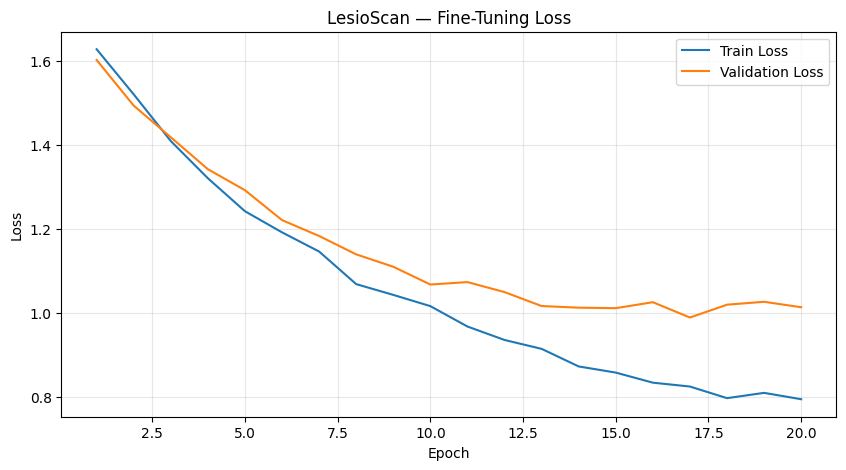

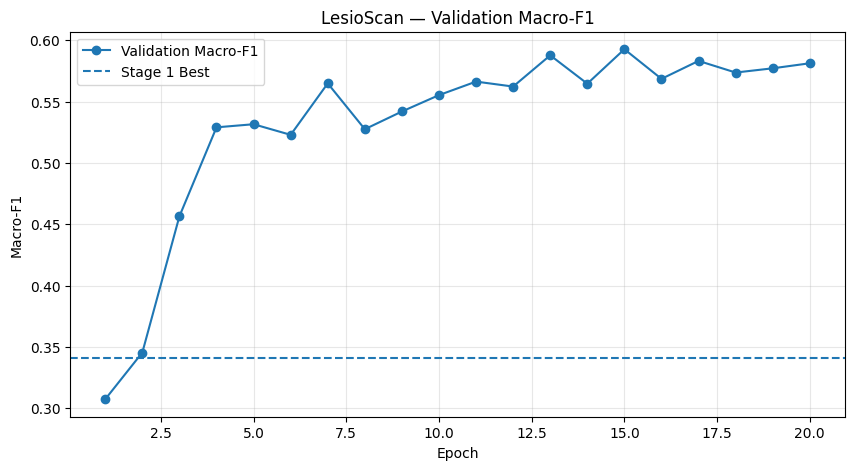

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

history = pd.read_csv(
    HISTORY_FT
)

display(history)

print("Stage 1 Best Macro-F1:", stage1_best_f1)
print(
    "Stage 2 Best Macro-F1:",
    history["val_macro_f1"].max()
)

plt.figure(figsize=(10, 5))

plt.plot(
    history["epoch"],
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    history["epoch"],
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LesioScan — Fine-Tuning Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    history["epoch"],
    history["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.axhline(
    stage1_best_f1,
    linestyle="--",
    label="Stage 1 Best"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("LesioScan — Validation Macro-F1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. Training history dan checkpoint

In [32]:
import json
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

# ==========================================
# PATH
# ==========================================

STAGE1_OUT = TRAIN_OUT
FINETUNE_OUT = TRAIN_OUT / "fine_tuning"

STAGE1_HISTORY = STAGE1_OUT / "history.csv"
STAGE2_HISTORY = FINETUNE_OUT / "history_finetuning.csv"

STAGE1_MODEL = STAGE1_OUT / "best_shufflenetv2.pt"
STAGE2_MODEL = FINETUNE_OUT / "best_finetuning.pt"

EVAL_OUT = TRAIN_OUT / "validation_evaluation"

FIGURES = EVAL_OUT / "figures"
TABLES = EVAL_OUT / "tables"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

# ==========================================
# LOAD HISTORY
# ==========================================

stage1 = pd.read_csv(STAGE1_HISTORY)
stage2 = pd.read_csv(STAGE2_HISTORY)

history = pd.concat(
    [stage1, stage2],
    ignore_index=True
)

history["global_epoch"] = range(
    1,
    len(history) + 1
)

display(history.tail(10))

# ==========================================
# BEST SCORES
# ==========================================

stage1_best = stage1["val_macro_f1"].max()
stage2_best = stage2["val_macro_f1"].max()

print("=" * 55)
print("LESIOSCAN — TRAINING SUMMARY")
print("=" * 55)

print(f"Stage 1 Best Macro-F1: {stage1_best:.4f}")
print(f"Stage 2 Best Macro-F1: {stage2_best:.4f}")
print(f"Improvement: {stage2_best - stage1_best:.4f}")

print("\nBest Stage 2 Epoch:")
display(
    stage2.loc[
        stage2["val_macro_f1"].idxmax()
    ].to_frame("value")
)

history.to_csv(
    TABLES / "combined_training_history.csv",
    index=False
)

,stage,epoch,train_loss,val_loss,train_macro_f1,val_macro_f1,val_balanced_accuracy,val_accuracy,global_epoch
15,fine_tuning,11,0.968211,1.073750,0.624977,0.566310,0.592437,0.678466,16
16,fine_tuning,12,0.936255,1.049963,0.630218,0.562262,0.605398,0.675516,17
17,fine_tuning,13,0.915128,1.016858,0.631262,0.587741,0.598527,0.707965,18
18,fine_tuning,14,0.873353,1.012958,0.656771,0.564612,0.585841,0.681416,19
19,fine_tuning,15,0.858758,1.011777,0.648750,0.592711,0.603596,0.696165,20
20,fine_tuning,16,0.834817,1.025976,0.668062,0.568542,0.589707,0.678466,21
21,fine_tuning,17,0.825640,0.989549,0.670304,0.583188,0.586587,0.681416,22
22,fine_tuning,18,0.798041,1.020063,0.657797,0.573694,0.594337,0.690265,23
23,fine_tuning,19,0.810612,1.026967,0.678408,0.577147,0.584833,0.678466,24
24,fine_tuning,20,0.795496,1.013989,0.676270,0.581258,0.602244,0.690265,25


LESIOSCAN — TRAINING SUMMARY
Stage 1 Best Macro-F1: 0.3409
Stage 2 Best Macro-F1: 0.5927
Improvement: 0.2518

Best Stage 2 Epoch:


,value
stage,fine_tuning
epoch,15
train_loss,0.858758
val_loss,1.011777
train_macro_f1,0.64875
val_macro_f1,0.592711
val_balanced_accuracy,0.603596
val_accuracy,0.696165


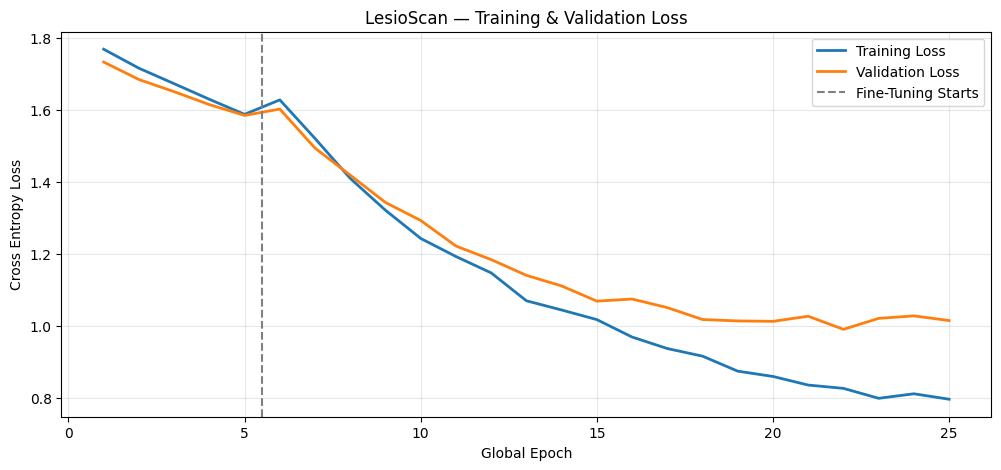

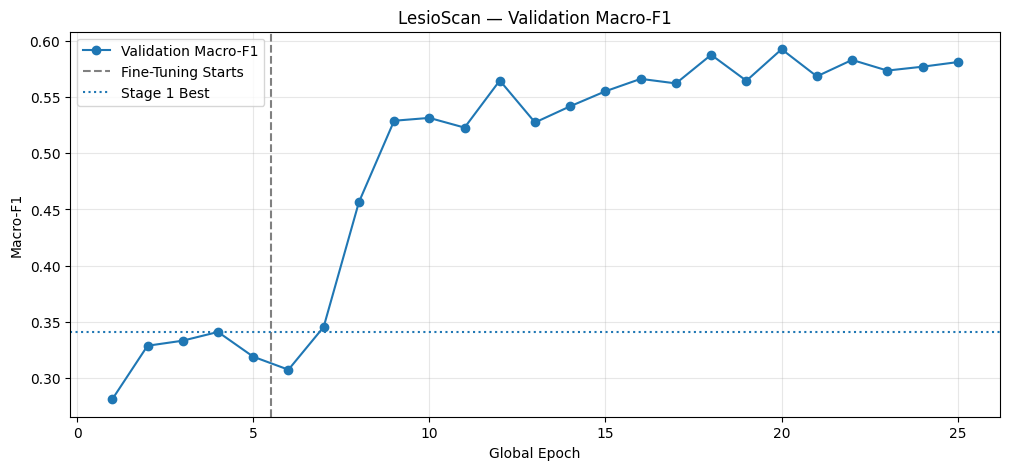

In [33]:
import matplotlib.pyplot as plt

# ==========================================
# LOSS CURVES
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(
    history["global_epoch"],
    history["train_loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    history["global_epoch"],
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.axvline(
    x=len(stage1) + 0.5,
    linestyle="--",
    color="gray",
    label="Fine-Tuning Starts"
)

plt.xlabel("Global Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("LesioScan — Training & Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    FIGURES / "training_loss.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# VALIDATION MACRO-F1
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(
    history["global_epoch"],
    history["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.axvline(
    x=len(stage1) + 0.5,
    linestyle="--",
    color="gray",
    label="Fine-Tuning Starts"
)

plt.axhline(
    y=stage1_best,
    linestyle=":",
    label="Stage 1 Best"
)

plt.xlabel("Global Epoch")
plt.ylabel("Macro-F1")
plt.title("LesioScan — Validation Macro-F1")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    FIGURES / "validation_macro_f1.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

In [34]:
import torch
from pathlib import Path

STAGE2_MODEL = TRAIN_OUT / "fine_tuning" / "best_finetuning.pt"

EVAL_MODEL = (
    TRAIN_OUT / "fine_tuning" / "best_finetuning_eval.pt"
)

assert STAGE2_MODEL.exists(), (
    f"Checkpoint tidak ditemukan: {STAGE2_MODEL}"
)

# Hanya gunakan weights_only=False untuk checkpoint
# yang benar-benar dibuat sendiri dan dipercaya.
checkpoint = torch.load(
    STAGE2_MODEL,
    map_location="cpu",
    weights_only=False
)

# Ambil informasi yang diperlukan untuk evaluasi.
evaluation_checkpoint = {
    "model": checkpoint["model"],
    "stage": checkpoint["stage"],
    "epoch": int(checkpoint["epoch"]),
    "classes": list(checkpoint["classes"]),
    "image_size": int(checkpoint["image_size"]),
    "model_state_dict": checkpoint["model_state_dict"],
}

torch.save(
    evaluation_checkpoint,
    EVAL_MODEL
)

print("✅ Checkpoint evaluasi berhasil dibuat")
print("Original:", STAGE2_MODEL)
print("Evaluation:", EVAL_MODEL)
print("Best epoch:", evaluation_checkpoint["epoch"])

✅ Checkpoint evaluasi berhasil dibuat
Original: /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/fine_tuning/best_finetuning.pt
Evaluation: /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/fine_tuning/best_finetuning_eval.pt
Best epoch: 15


In [35]:
import sys
import torch
from pathlib import Path

sys.path.insert(0, str(REPO / "src"))

from lesioscan.training import make_model
from lesioscan.preprocessing import CLASSES

# ==========================================
# PATH
# ==========================================

STAGE2_MODEL = (
    TRAIN_OUT
    / "fine_tuning"
    / "best_finetuning.pt"
)

EVAL_MODEL = (
    TRAIN_OUT
    / "fine_tuning"
    / "best_finetuning_eval.pt"
)

assert STAGE2_MODEL.exists(), (
    f"Checkpoint tidak ditemukan: {STAGE2_MODEL}"
)

# ==========================================
# CONVERT CHECKPOINT
# ==========================================

# Hanya untuk checkpoint yang dibuat sendiri
# dan berasal dari sumber tepercaya.
if not EVAL_MODEL.exists():

    original = torch.load(
        STAGE2_MODEL,
        map_location="cpu",
        weights_only=False
    )

    evaluation_checkpoint = {
        "model": original["model"],
        "stage": original["stage"],
        "epoch": int(original["epoch"]),
        "classes": list(original["classes"]),
        "image_size": int(original["image_size"]),
        "model_state_dict": original["model_state_dict"],
    }

    torch.save(
        evaluation_checkpoint,
        EVAL_MODEL
    )

# ==========================================
# LOAD EVALUATION CHECKPOINT
# ==========================================

checkpoint = torch.load(
    EVAL_MODEL,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["model"] == "shufflenet_v2_x1_0"
assert checkpoint["classes"] == list(CLASSES)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = make_model(pretrained=False)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

print("✅ Checkpoint berhasil dimuat")
print("Model:", checkpoint["model"])
print("Stage:", checkpoint["stage"])
print("Best Epoch:", checkpoint["epoch"])
print("Device:", DEVICE)
print("Classes:", checkpoint["classes"])

✅ Checkpoint berhasil dimuat
Model: shufflenet_v2_x1_0
Stage: fine_tuning
Best Epoch: 15
Device: cuda
Classes: ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']


## 6. Interpretasi dan langkah berikutnya

- Laporkan validation Macro-F1, balanced accuracy, train/val loss.
- Waspadai overfitting dan MEL recall yang rentan tidak stabil.
- Jangan gunakan test split untuk menentukan epoch/model.
- Benchmark DenseNet121 dan ViT-Small memakai split dan preprocessing yang setara.
- Checkpoint ini untuk eksperimen edukatif; **bukan model diagnosis klinis**.